# Trend-aware drift correction and a test in time

`01_year3_drift_sensitivity` found that the base period matters more than the year-3 method:
P(La Niña 2027/28) is 0.30 with the drift of the 1981-2010 starts and 0.57 with 1991-2018, and the
difference comes from the drift itself (the observed climatologies differ by only 0.06 °C). The model's drift
is trending over the start years. This notebook turns that into a choice:

1. **Trend-aware correction** (Kharin et al. 2012), at each lead *L*, over the start years *y*:
   * **T1, trend in the drift:** $d_L(y) = a_L + b_L\,y$ (model ensemble mean minus observed); the forecast is
     corrected with $d_L(2026)$ and its anomaly taken from the observed climatology of `OBS_BASE`.
   * **T2, trend in the climatology:** the model's lead-time climatology $c_L(y) = a_L + b_L\,y$ is removed from
     the forecast, and observed anomalies are taken from the observed linear trend of each calendar month
     (both anomalies are then relative to a moving, trend-following base).
2. **Test in time:** every method is built from the 1981-2008 starts only and verified on the 2009-2018 starts:
   mean bias, RMSE and the Brier score for La Niña (DJF ≤ −0.5 °C) in years 1 and 2 (10 members, 10 years).
   The method that verifies best on the recent starts is the one to trust for 2026.

Year 3 of the 2026 forecast uses the adjusted, $r = 1$ extension of `01_year3_drift_sensitivity` for every
method.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/03_drift_trend_and_test"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/03_drift_trend_and_test/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"

YEAR, INIT = 2026, 11
NLEAD_REF = rc.NLEAD
NLEAD = rc.start_nlead(YEAR, INIT)
REF_YEARS = (1981, 2018)
OBS_BASE = (1991, 2020)                     # observed climatology for the fixed and T1 anomalies (CPC's current base)
TRAIN, VERIFY = (1981, 2008), (2009, 2018)  # test in time
# methods: (kind, start years used[, year the trend is evaluated at]); kind: "fixed" (mean drift),
# "T1" (linear trend in the drift), "T2" (Kharin: linear trend in the model climatology). Without an
# evaluation year the trend is evaluated at the forecast's start year (extrapolated); "at 2018" holds it at
# the last start (no extrapolation past the data).
METHODS_2026 = {
    "fixed 1981-2010": ("fixed", (1981, 2010)),
    "fixed 1991-2018": ("fixed", (1991, 2018)),
    "fixed 2004-2018 (last 15)": ("fixed", (2004, 2018)),
    "T1 drift trend, at 2018": ("T1", (1981, 2018), 2018),
    "T2 climatology trend, at 2018": ("T2", (1981, 2018), 2018),
    "T1 drift trend, at 2026": ("T1", (1981, 2018)),
    "T2 climatology trend, at 2026": ("T2", (1981, 2018)),
}
METHODS_TEST = {
    "fixed 1981-2008": ("fixed", (1981, 2008)),
    "fixed 1991-2008": ("fixed", (1991, 2008)),
    "fixed 1994-2008 (last 15)": ("fixed", (1994, 2008)),
    "T1 drift trend": ("T1", (1981, 2008)),
    "T2 climatology trend": ("T2", (1981, 2008)),
}
COLORS = ["tab:red", "tab:orange", "tab:olive", "tab:cyan", "tab:pink", "tab:blue", "tab:purple"]
POOL = {name: rc.CASES[name]["case_prefix"] for name in rc.POOLED_CASES}
NINO_BOX = rc.NINO_REGIONS["Nino3.4"]
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)
OBS_PRODUCT = "HadISST1.1"
THRESHOLD = -0.5
WINTERS = {"2026/27": 1, "2027/28": 13, "2028/29": 25}
DJF_LEADS = {"year 1": 1, "year 2": 13}
ADJUST_LEADS = 3
N_BOOT = 2000

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load: member-level indices (cached)

Niño3.4 and the tropical ocean mean of every member of the Reanalysis 1 Nov starts (the Brier score needs
members), the 30 members of the 2026 start, and HadISST 1.1; absolute °C.

In [3]:
%%time
CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                    f"nino34_trop_members_init{INIT:02d}_ref{REF_YEARS[0]}-{REF_YEARS[1]}_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
EXPECTED = {"ref_years": f"{REF_YEARS[0]}-{REF_YEARS[1]}", "year": YEAR, "init": INIT, "nlead": NLEAD,
            "pool": ",".join(POOL), "obs": OBS_PRODUCT}


def build():
    ocean = rc.land_fraction() < 0.5
    idx = lambda da: (rc.box_mean(da, NINO_BOX).load(), rc.box_mean(da.where(ocean), TROPICAL_BOX).load())
    rn = np.full((REF_YEARS[1] - REF_YEARS[0] + 1, rc.NENS, NLEAD_REF), np.nan)
    rt = rn.copy()
    for k, y in enumerate(range(REF_YEARS[0], REF_YEARS[1] + 1)):
        ens = rc.open_hindcast(rc.REFERENCE["case_prefix"], y, INIT, "TS")
        if ens is None:
            continue
        n, t = idx(ens)
        rn[k, ens["member"].values], rt[k, ens["member"].values] = n.values, t.values
    fn, ft, members = [], [], []
    for name, prefix in POOL.items():
        ens = rc.open_hindcast(prefix, YEAR, INIT, "TS")
        n, t = idx(ens)
        fn.append(n.values), ft.append(t.values)
        members += [f"{rc.CASES[name]['short']}:{m}" for m in ens["member"].values]
    obs = rc.obs_monthly("TS", years=(REF_YEARS[0], YEAR), mode=derivation_mode, product=OBS_PRODUCT)
    on, ot = idx(obs)
    ds = xr.Dataset(
        {"ref_nino": (("year", "ens", "lead"), rn), "ref_trop": (("year", "ens", "lead"), rt),
         "fc_nino": (("member", "flead"), np.concatenate(fn)), "fc_trop": (("member", "flead"), np.concatenate(ft)),
         "obs_nino": ("time", on.values), "obs_trop": ("time", ot.values)},
        coords={"year": np.arange(REF_YEARS[0], REF_YEARS[1] + 1), "ens": np.arange(rc.NENS), "lead": np.arange(NLEAD_REF),
                "member": members, "flead": np.arange(NLEAD),
                "time": [f"{t.year:04d}-{t.month:02d}" for t in obs["time"].to_index()]})
    ds.attrs.update(EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and CACHE.is_file() and all(
        str(load_netcdf(CACHE).attrs.get(k)) == str(v) for k, v in EXPECTED.items()):
    D = load_netcdf(CACHE)
else:
    D = build()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    atomic_to_netcdf(D, CACHE)
print(f"Reanalysis Nov starts {int(D.year[0])}-{int(D.year[-1])}, {D.sizes['ens']} members each; "
      f"{D.sizes['member']} forecast members; HadISST {str(D.time.values[0])} to {str(D.time.values[-1])}")

Reanalysis Nov starts 1981-2018, 10 members each; 30 forecast members; HadISST 1981-01 to 2026-09
CPU times: user 687 ms, sys: 341 ms, total: 1.03 s
Wall time: 1.06 s


### Helpers

All arrays are absolute °C. `kind` "Nino3.4" or "Relative" (Niño3.4 minus the tropical mean; not rescaled
here, since every method is compared on the same index).

In [4]:
OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
OBS_T = pd.Series(D["obs_trop"].values, index=OBS.index)


def target(y, lead):
    return pd.Period(year=int(y), month=INIT, freq="M") + int(lead)


def data(kind):
    # Reanalysis members (year, ens, lead), forecast members (member, lead), observed series
    if kind == "Nino3.4":
        return D["ref_nino"].values, D["fc_nino"].values, OBS
    return (D["ref_nino"] - D["ref_trop"]).values, (D["fc_nino"] - D["fc_trop"]).values, OBS - OBS_T


YEARS = D["year"].values


def obs_at(obs, years, leads):
    return np.array([[obs.get(target(y, L), np.nan) for L in leads] for y in years])


def obs_clim(obs, base):
    sel = obs[(obs.index.year >= base[0]) & (obs.index.year <= base[1])]
    return sel.groupby(sel.index.month).mean()


def obs_trend(obs, years_fit):
    # per calendar month: linear trend of the observed series over years_fit -> function (year, month) -> value
    coef = {}
    for m in range(1, 13):
        s = obs[(obs.index.month == m) & (obs.index.year >= years_fit[0]) & (obs.index.year <= years_fit[1])]
        coef[m] = np.polyfit(s.index.year, s.values, 1)
    return lambda yr, m: np.polyval(coef[m], yr)


def extend(c):
    # 24 -> NLEAD leads: c3 = c2 + (c2 - c1), the change from leads >= ADJUST_LEADS (r = 1, adjusted)
    delta = c[12:24] - c[:12]
    delta = np.where(np.arange(12) < ADJUST_LEADS, delta[ADJUST_LEADS:].mean(), delta)
    return np.r_[c[:24], c[12:24] + delta]


def trend_parts(years, x, ty):
    # by lead: (mean over the start years, linear-trend term at ty); their sum is the fitted line at ty
    yd = years - years.mean()
    return x.mean(0), (yd @ (x - x.mean(0)) / (yd @ yd)) * (ty - years.mean())


def extend_parts(base, term, nlead):
    # leads >= 24: the mean part by extend() (target month); the trend term depends on lead, not on target
    # month, so it holds its lead-23 value (copying it by target month makes a step at lead 24)
    if nlead <= NLEAD_REF:
        return (base + term)[:nlead]
    return extend(base)[:nlead] + np.r_[term, np.full(nlead - NLEAD_REF, term[-1])]


def correction(kind, method, starts, eval_year, nlead, trend_year=None):
    # (subtract from model, anomaly reference of the target months) for a start in eval_year:
    # model anomaly = model - sub ; observed anomaly = obs - ref. trend_year: evaluate a trend there instead
    ref, _, obs = data(kind)
    ty = eval_year if trend_year is None else trend_year
    sel = (YEARS >= starts[0]) & (YEARS <= starts[1])
    years = YEARS[sel]
    ens_mean = np.nanmean(ref[sel], axis=1)                         # (year, lead)
    o = obs_at(obs, years, range(NLEAD_REF))                        # (year, lead)
    months = [target(eval_year, L).month for L in range(nlead)]
    if method == "fixed":
        d = np.nanmean(ens_mean - o, axis=0)
        clim = obs_clim(obs, OBS_BASE).loc[months].values
        return (extend(d)[:nlead] if nlead > 24 else d[:nlead]) + clim, clim
    if method == "T1":
        base, term = trend_parts(years, ens_mean - o, ty)
        clim = obs_clim(obs, OBS_BASE).loc[months].values
        return extend_parts(base, term, nlead) + clim, clim
    # T2: model climatology trend; observed reference: observed trend of each calendar month (same years)
    base, term = trend_parts(years, ens_mean, ty)
    tr = obs_trend(obs, (starts[0], starts[1] + 2))
    oref = np.array([tr(target(ty, L).year, target(ty, L).month) for L in range(nlead)])
    return extend_parts(base, term, nlead), oref


def djf(a, first):
    return a[..., first:first + 3].mean(-1)

### 1. How the drift trends with the start year

Drift (Reanalysis ensemble mean minus HadISST) of the DJF of years 1 and 2 against the start year, with the
linear fit (T1) and the two fixed means. The fitted value at 2026 is where T1 corrects the forecast.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/03_drift_trend_and_test/figures/fig_drift_trend_djf_drift_vs_start_year.png


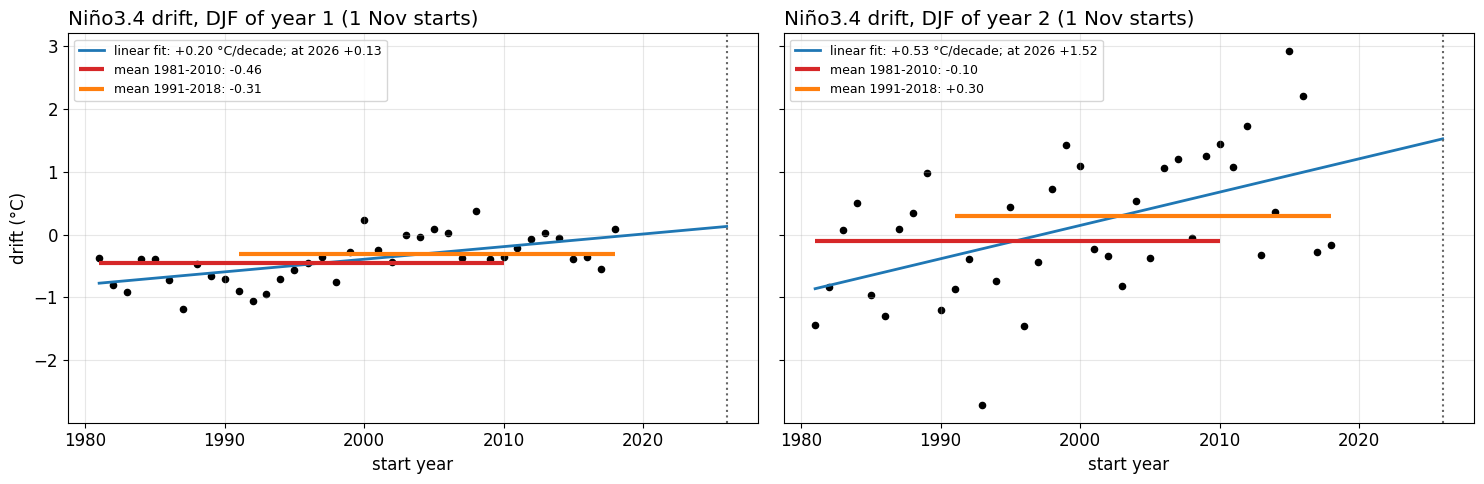

,winter,trend (°C/decade),r with year,T1 at 2026
0,year 1,0.20,0.61,0.13
1,year 2,0.53,0.52,1.52


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
rows = []
ref, _, obs = data("Nino3.4")
ens_mean = np.nanmean(ref, axis=1)
o = obs_at(obs, YEARS, range(NLEAD_REF))
for ax, (lab, first) in zip(axes, DJF_LEADS.items()):
    dd = djf(ens_mean - o, first)
    ok = np.isfinite(dd)
    b, a = np.polyfit(YEARS[ok], dd[ok], 1)
    ax.scatter(YEARS, dd, color="k", s=20)
    yy = np.array([YEARS[0], YEAR])
    ax.plot(yy, a + b * yy, color="tab:blue", lw=2, label=f"linear fit: {10 * b:+.2f} °C/decade; at 2026 {a + b * YEAR:+.2f}")
    for (s0, s1), c in (((1981, 2010), "tab:red"), ((1991, 2018), "tab:orange")):
        m = dd[(YEARS >= s0) & (YEARS <= s1)].mean()
        ax.hlines(m, s0, s1, color=c, lw=3, label=f"mean {s0}-{s1}: {m:+.2f}")
    ax.axvline(YEAR, color="0.4", ls=":")
    ax.set_title(f"Niño3.4 drift, DJF of {lab} (1 Nov starts)", loc="left")
    ax.set_xlabel("start year")
    ax.legend(fontsize=9)
    r_, p_ = np.corrcoef(YEARS[ok], dd[ok])[0, 1], None
    rows.append({"winter": lab, "trend (°C/decade)": round(10 * b, 2), "r with year": round(r_, 2),
                 "T1 at 2026": round(a + b * YEAR, 2)})
axes[0].set_ylabel("drift (°C)")
fig.tight_layout()
save(fig, "drift_trend", "djf_drift_vs_start_year")
plt.show()
display(pd.DataFrame(rows))

### 2. Test in time: train on the 1981-2008 starts, verify on 2009-2018

For every verification start: corrected member anomalies against the observed anomaly (same reference for
both, per method). Mean bias, RMSE (ensemble mean) and the Brier score of the La Niña probability (member
fraction ≤ −0.5 °C) for the DJF of years 1 and 2; the 90% bootstrap interval (verification years resampled)
of each score's difference from "fixed 1981-2008". Bottom: the mean bias by lead.

,index,method,winter,mean bias (°C),RMSE (°C),Brier (La Niña),observed La Niña
0,Nino3.4,fixed 1981-2008,year 1,0.24,0.31,0.013,3
1,Nino3.4,fixed 1981-2008,year 2,1.23,1.62,0.239,3
2,Nino3.4,fixed 1991-2008,year 1,0.13,0.24,0.008,3
3,Nino3.4,fixed 1991-2008,year 2,1.13,1.55,0.220,3
4,Nino3.4,fixed 1994-2008 (last 15),year 1,0.01,0.20,0.016,3
5,Nino3.4,fixed 1994-2008 (last 15),year 2,0.89,1.38,0.235,3
6,Nino3.4,T1 drift trend,year 1,-0.36,0.42,0.152,3
7,Nino3.4,T1 drift trend,year 2,0.41,1.17,0.216,3
8,Nino3.4,T2 climatology trend,year 1,-0.09,0.22,0.013,3
9,Nino3.4,T2 climatology trend,year 2,0.40,1.16,0.246,3


,index,method,winter,metric,difference from fixed 1981-2008,90% interval
0,Nino3.4,fixed 1991-2008,year 1,Brier,-0.005,-0.015 to +0.000
1,Nino3.4,fixed 1991-2008,year 1,MSE,-0.040,-0.062 to -0.018
2,Nino3.4,fixed 1991-2008,year 2,Brier,-0.019,-0.057 to +0.000
3,Nino3.4,fixed 1991-2008,year 2,MSE,-0.226,-0.328 to -0.120
4,Nino3.4,fixed 1994-2008 (last 15),year 1,Brier,0.003,-0.018 to +0.027
5,Nino3.4,fixed 1994-2008 (last 15),year 1,MSE,-0.057,-0.103 to -0.010
6,Nino3.4,fixed 1994-2008 (last 15),year 2,Brier,-0.004,-0.044 to +0.025
7,Nino3.4,fixed 1994-2008 (last 15),year 2,MSE,-0.716,-1.074 to -0.342
8,Nino3.4,T1 drift trend,year 1,Brier,0.139,+0.007 to +0.304
9,Nino3.4,T1 drift trend,year 1,MSE,0.079,-0.054 to +0.219


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/03_drift_trend_and_test/figures/fig_drift_trend_test_in_time_bias_by_lead.png


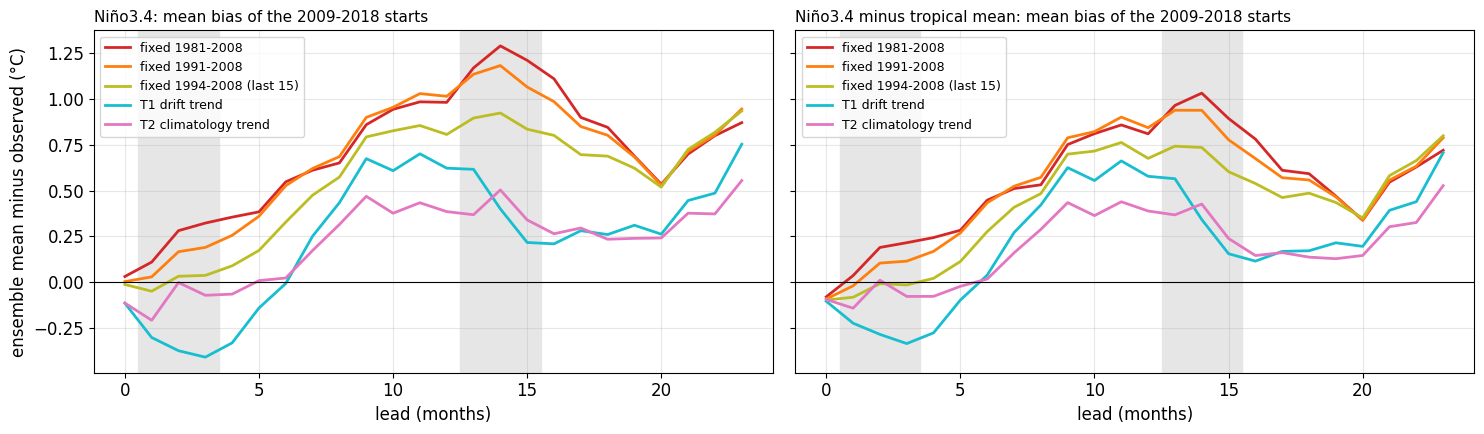

In [6]:
def verify(kind, method_key, methods):
    method, starts = methods[method_key][:2]
    ref, _, obs = data(kind)
    out = {"fc": [], "ob": []}
    for y in range(VERIFY[0], VERIFY[1] + 1):
        sub, oref = correction(kind, method, starts, y, NLEAD_REF)
        k = int(np.where(YEARS == y)[0][0])
        out["fc"].append(ref[k] - sub[None, :])                     # (ens, lead)
        out["ob"].append(np.array([obs[target(y, L)] for L in range(NLEAD_REF)]) - oref)
    return np.array(out["fc"]), np.array(out["ob"])                 # (year, ens, lead), (year, lead)


rows, bias_by_lead, scores = [], {}, {}
for kind in ("Nino3.4", "Relative"):
    for mkey in METHODS_TEST:
        fc, ob = verify(kind, mkey, METHODS_TEST)
        em = np.nanmean(fc, axis=1)
        bias_by_lead[(kind, mkey)] = np.nanmean(em - ob, axis=0)
        for lab, first in DJF_LEADS.items():
            f, o_, e = djf(fc, first), djf(ob, first), djf(em, first)
            p = np.nanmean(f <= THRESHOLD, axis=1)
            evt = (o_ <= THRESHOLD).astype(float)
            scores[(kind, mkey, lab)] = {"bias": e - o_, "se": (e - o_) ** 2, "bs": (p - evt) ** 2}
            rows.append({"index": kind, "method": mkey, "winter": lab, "mean bias (°C)": round(np.mean(e - o_), 2),
                         "RMSE (°C)": round(np.sqrt(np.mean((e - o_) ** 2)), 2), "Brier (La Niña)": round(np.mean((p - evt) ** 2), 3),
                         "observed La Niña": int(evt.sum())})
test = pd.DataFrame(rows)

rng = np.random.default_rng(0)
nyr = VERIFY[1] - VERIFY[0] + 1
boot = rng.integers(0, nyr, (N_BOOT, nyr))
base_key = list(METHODS_TEST)[0]
ci = []
for (kind, mkey, lab), s in scores.items():
    if mkey == base_key:
        continue
    b0 = scores[(kind, base_key, lab)]
    for metric in ("bs", "se"):
        diff = s[metric][boot].mean(1) - b0[metric][boot].mean(1)
        ci.append({"index": kind, "method": mkey, "winter": lab,
                   "metric": "Brier" if metric == "bs" else "MSE",
                   "difference from fixed 1981-2008": round(float(np.mean(s[metric] - b0[metric])), 3),
                   "90% interval": f"{np.percentile(diff, 5):+.3f} to {np.percentile(diff, 95):+.3f}"})
test.to_csv(DATA_DIR / "test_in_time_2009_2018.csv", index=False)
display(test)
display(pd.DataFrame(ci))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, kind in zip(axes, ("Nino3.4", "Relative")):
    for mkey, c in zip(METHODS_TEST, COLORS):
        ax.plot(range(NLEAD_REF), bias_by_lead[(kind, mkey)], color=c, lw=2, label=mkey)
    ax.axhline(0, color="k", lw=0.8)
    for first in DJF_LEADS.values():
        ax.axvspan(first - 0.5, first + 2.5, color="0.9", zorder=0)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean'}: mean bias of the 2009-2018 starts", loc="left", fontsize=11)
    ax.set_xlabel("lead (months)")
    ax.legend(fontsize=9)
axes[0].set_ylabel("ensemble mean minus observed (°C)")
fig.tight_layout()
save(fig, "drift_trend", "test_in_time_bias_by_lead")
plt.show()

### 3. The 1 Nov 2026 forecast with each correction

Corrected anomalies of the 30 pooled members, with P(La Niña) for each winter. Year 3: the mean drift (or
model climatology) by the adjusted $r = 1$ rule, which works by target month; the trend term of T1/T2
depends on lead, not target month, and holds its lead-23 value. The last column is the ensemble-mean step
from Oct to Nov 2028 (lead 23 → 24), the continuity check of `01`.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/03_drift_trend_and_test/figures/fig_drift_trend_nov2026_by_method.png


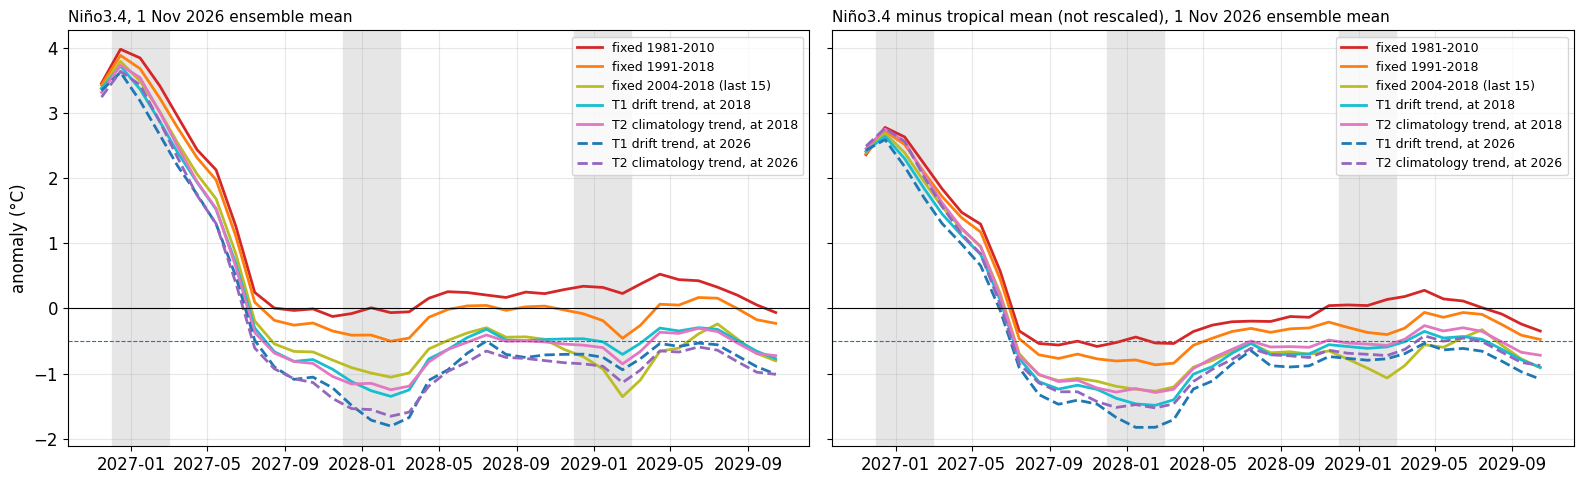

,index,method,DJF 27/28 mean,P(LN 27/28),DJF 28/29 mean,P(LN 28/29),P(both),step Oct→Nov 2028 (°C)
0,Nino3.4,fixed 1981-2010,-0.04,0.30,0.30,0.27,0.10,0.06
1,Nino3.4,fixed 1991-2018,-0.44,0.57,-0.24,0.40,0.23,-0.06
2,Nino3.4,fixed 2004-2018 (last 15),-0.98,0.73,-1.01,0.63,0.50,-0.16
3,Nino3.4,"T1 drift trend, at 2018",-1.24,0.80,-0.56,0.50,0.40,0.01
4,Nino3.4,"T2 climatology trend, at 2018",-1.18,0.80,-0.67,0.50,0.40,-0.03
5,Nino3.4,"T1 drift trend, at 2026",-1.67,0.87,-0.80,0.60,0.57,0.01
6,Nino3.4,"T2 climatology trend, at 2026",-1.58,0.83,-0.96,0.63,0.57,-0.03
7,Relative,fixed 1981-2010,-0.50,0.57,0.08,0.27,0.17,0.18
8,Relative,fixed 1991-2018,-0.82,0.73,-0.35,0.43,0.30,0.09
9,Relative,fixed 2004-2018 (last 15),-1.23,0.80,-0.92,0.60,0.50,0.05


In [7]:
rows = []
x = [target(YEAR, L).to_timestamp() + pd.Timedelta(days=14) for L in range(NLEAD)]
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, kind in zip(axes, ("Nino3.4", "Relative")):
    _, fc, _ = data(kind)
    for (mkey, spec), c in zip(METHODS_2026.items(), COLORS):
        sub, oref = correction(kind, spec[0], spec[1], YEAR, NLEAD, trend_year=spec[2] if len(spec) > 2 else None)
        a = fc - sub[None, :]                                       # model anomaly (member, lead)
        ax.plot(x, a.mean(0), color=c, lw=2, ls="--" if "2026" in mkey else "-", label=mkey)
        v = {w: djf(a, first) for w, first in WINTERS.items()}
        ln = {w: v[w] <= THRESHOLD for w in v}
        rows.append({"index": kind, "method": mkey, "DJF 27/28 mean": round(v["2027/28"].mean(), 2),
                     "P(LN 27/28)": round(ln["2027/28"].mean(), 2), "DJF 28/29 mean": round(v["2028/29"].mean(), 2),
                     "P(LN 28/29)": round(ln["2028/29"].mean(), 2), "P(both)": round((ln["2027/28"] & ln["2028/29"]).mean(), 2),
                     "step Oct→Nov 2028 (°C)": round(float(a.mean(0)[NLEAD_REF] - a.mean(0)[NLEAD_REF - 1]), 2)})
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
    for first in WINTERS.values():
        ax.axvspan(x[first] - pd.Timedelta(days=14), x[first + 2] + pd.Timedelta(days=14), color="0.9", zorder=0)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean (not rescaled)'}, 1 Nov 2026 ensemble mean",
                 loc="left", fontsize=11)
    ax.legend(fontsize=9)
axes[0].set_ylabel("anomaly (°C)")
fig.tight_layout()
save(fig, "drift_trend", "nov2026_by_method")
plt.show()
p2026 = pd.DataFrame(rows)
p2026.to_csv(DATA_DIR / "nov2026_la_nina_by_drift_method.csv", index=False)
display(p2026)

### 3b. Sensitivity to the fixed base period

The 1 Nov 2026 forecast with the mean drift of a fixed window of start years. **Default: 1981-2010** (the current
approach; black), against sliding **15-year windows** stepped by 5 years from 1981 to 2018 (the Reanalysis Nov
starts begin in 1981; the last window is aligned to end in 2018). The observed reference is the same for every
line, the observed 1981-2010 climatology, so the lines differ only by the model's drift. Year 3 by the adjusted
$r = 1$ rule as above. Shading: 10-90% of the 30 members for the default. Right: DJF means against the window's
centre year (the 1981-2010 value as the horizontal line).

**Result (Niño3.4).** The windows centred before 2000 give a forecast warmer than the default (DJF 2027/28
+0.14 to +0.41 °C, P(La Niña 2027/28) 0.10-0.23, against −0.02 °C and 0.30 for 1981-2010); the windows from
1996-2010 on give a much cooler one (−0.46, −0.75, −0.96 °C; P(La Niña 2027/28) 0.57, 0.70, 0.73; P(La Niña
2028/29) 0.40-0.63). The change is not gradual: the 1991-2005 and 1996-2010 windows differ by 0.6 °C in DJF
2027/28 (0.8 °C in 2028/29), so the drift shift sits in the starts after about 2005, the same starts that
set the drift trend of section 1. The relative index shifts the same way (P(La Niña 2027/28) 0.33-0.53 →
0.73-0.83), and the year-1 peak differs by only ≈0.5 °C across windows. The 1981-2010 default lies between the early
windows and 1996-2010, closer to the early ones.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/03_drift_trend_and_test/figures/fig_drift_trend_nov2026_by_fixed_base.png


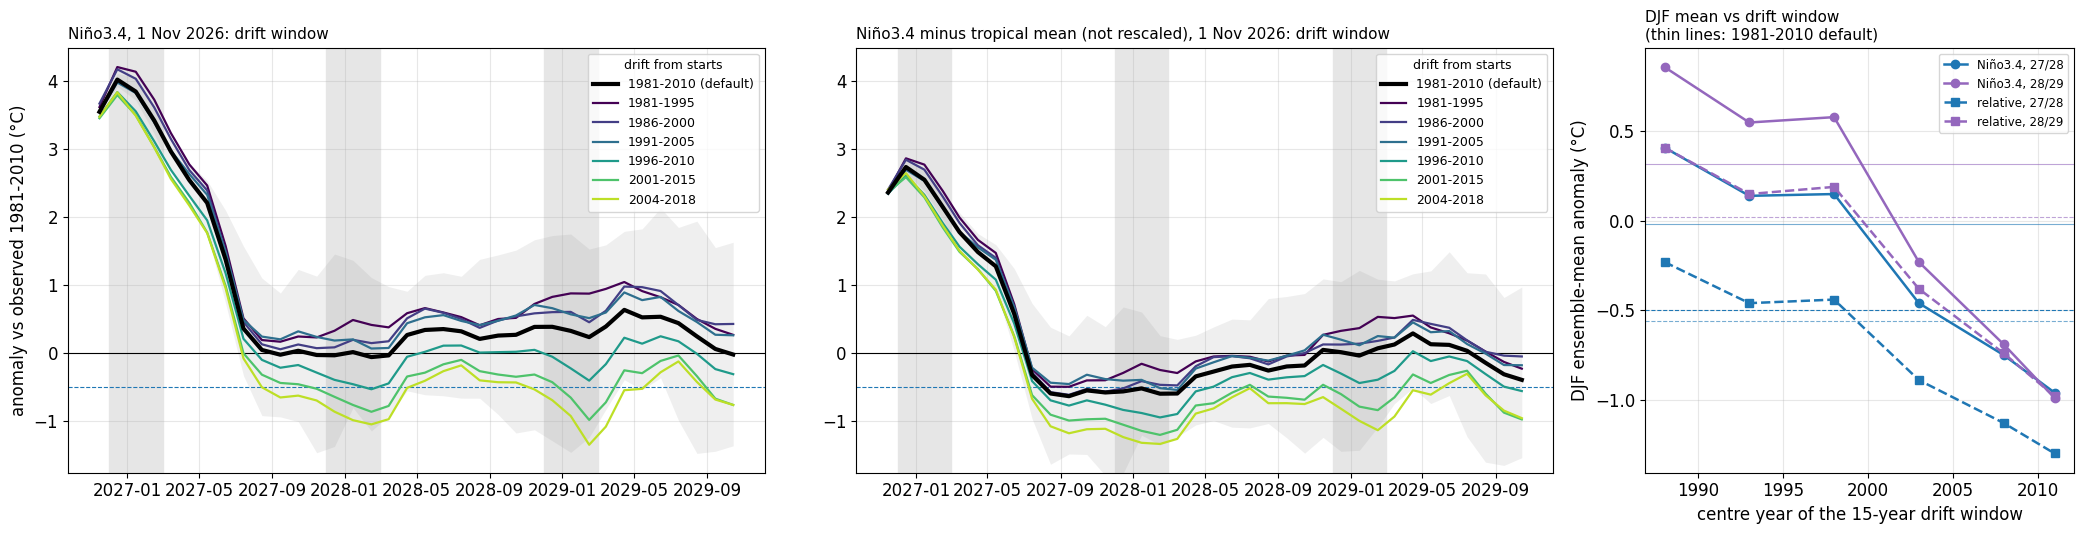

,index,drift starts,DJF 26/27 mean,DJF 27/28 mean,P(LN 27/28),DJF 28/29 mean,P(LN 28/29),P(both),step Oct→Nov 2028 (°C)
0,Nino3.4,1981-2010 (default),3.76,-0.02,0.30,0.32,0.27,0.10,0.12
1,Nino3.4,1981-1995,4.02,0.41,0.10,0.86,0.13,0.03,0.20
2,Nino3.4,1986-2000,3.94,0.14,0.23,0.55,0.20,0.10,0.04
3,Nino3.4,1991-2005,3.73,0.15,0.23,0.58,0.20,0.10,0.15
4,Nino3.4,1996-2010,3.50,-0.46,0.57,-0.23,0.40,0.23,0.03
5,Nino3.4,2001-2015,3.44,-0.75,0.70,-0.69,0.50,0.37,0.03
6,Nino3.4,2004-2018,3.45,-0.96,0.73,-0.99,0.63,0.50,-0.10
7,Relative,1981-2010 (default),2.48,-0.56,0.60,0.02,0.30,0.17,0.23
8,Relative,1981-1995,2.67,-0.23,0.33,0.41,0.17,0.07,0.29
9,Relative,1986-2000,2.61,-0.46,0.53,0.15,0.27,0.13,0.13


In [8]:
DEFAULT_BASE = (1981, 2010)
WINDOW, STEP = 15, 5
BASES = {f"{DEFAULT_BASE[0]}-{DEFAULT_BASE[1]} (default)": DEFAULT_BASE}
starts15 = list(range(int(YEARS[0]), int(YEARS[-1]) - WINDOW + 2, STEP))
if starts15[-1] + WINDOW - 1 < YEARS[-1]:
    starts15.append(int(YEARS[-1]) - WINDOW + 1)
BASES.update({f"{s}-{s + WINDOW - 1}": (s, s + WINDOW - 1) for s in starts15})
base_colors = ["k"] + list(plt.cm.viridis(np.linspace(0, 0.9, len(starts15))))
rows = []
x = [target(YEAR, L).to_timestamp() + pd.Timedelta(days=14) for L in range(NLEAD)]
months = [target(YEAR, L).month for L in range(NLEAD)]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={"width_ratios": [1.3, 1.3, 0.8]})
for ax, kind in zip(axes[:2], ("Nino3.4", "Relative")):
    _, fc, obs = data(kind)
    ref_clim = obs_clim(obs, DEFAULT_BASE).loc[months].values
    for (lab, win), c in zip(BASES.items(), base_colors):
        sub, clim = correction(kind, "fixed", win, YEAR, NLEAD)
        a = fc - (sub - clim + ref_clim)[None, :]                   # drift of win, observed 1981-2010 reference
        default = win == DEFAULT_BASE
        ax.plot(x, a.mean(0), color=c, lw=3 if default else 1.6, zorder=5 if default else 3, label=lab)
        if default:
            ax.fill_between(x, *np.percentile(a, [10, 90], axis=0), color="0.5", alpha=0.12, lw=0)
        v = {w: djf(a, first) for w, first in WINTERS.items()}
        ln = {w: v[w] <= THRESHOLD for w in v}
        rows.append({"index": kind, "drift starts": lab, "centre": np.mean(win),
                     "DJF 26/27 mean": round(v["2026/27"].mean(), 2), "DJF 27/28 mean": round(v["2027/28"].mean(), 2),
                     "P(LN 27/28)": round(ln["2027/28"].mean(), 2), "DJF 28/29 mean": round(v["2028/29"].mean(), 2),
                     "P(LN 28/29)": round(ln["2028/29"].mean(), 2), "P(both)": round((ln["2027/28"] & ln["2028/29"]).mean(), 2),
                     "step Oct→Nov 2028 (°C)": round(float(a.mean(0)[NLEAD_REF] - a.mean(0)[NLEAD_REF - 1]), 2)})
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
    for first in WINTERS.values():
        ax.axvspan(x[first] - pd.Timedelta(days=14), x[first + 2] + pd.Timedelta(days=14), color="0.9", zorder=0)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean (not rescaled)'}, 1 Nov 2026: drift window",
                 loc="left", fontsize=11)
    ax.legend(fontsize=9, loc="upper right", title="drift from starts", title_fontsize=9)
axes[0].set_ylabel(f"anomaly vs observed {DEFAULT_BASE[0]}-{DEFAULT_BASE[1]} (°C)")
axes[1].sharey(axes[0])
p_base = pd.DataFrame(rows)
ax = axes[2]
for kind, ls, mk in (("Nino3.4", "-", "o"), ("Relative", "--", "s")):
    sub = p_base[(p_base["index"] == kind) & ~p_base["drift starts"].str.contains("default")]
    dflt = p_base[(p_base["index"] == kind) & p_base["drift starts"].str.contains("default")].iloc[0]
    for col, c in (("DJF 27/28 mean", "tab:blue"), ("DJF 28/29 mean", "tab:purple")):
        ax.plot(sub["centre"], sub[col], color=c, ls=ls, marker=mk, lw=1.8,
                label=f"{'Niño3.4' if kind == 'Nino3.4' else 'relative'}, {col.split()[1]}")
        ax.axhline(dflt[col], color=c, ls=ls, lw=0.8, alpha=0.6)
ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
ax.set_xlabel(f"centre year of the {WINDOW}-year drift window")
ax.set_ylabel("DJF ensemble-mean anomaly (°C)")
ax.set_title("DJF mean vs drift window\n(thin lines: 1981-2010 default)", loc="left", fontsize=11)
ax.legend(fontsize=8.5)
fig.tight_layout()
save(fig, "drift_trend", "nov2026_by_fixed_base")
plt.show()
p_base.to_csv(DATA_DIR / "nov2026_la_nina_by_fixed_base.csv", index=False)
display(p_base.drop(columns="centre"))

### 3c. Sensitivity of the trend correction to the training starts

The same figure as 3b, but every line is the trend correction (T1, TrDC in `05`), fitted on a window of start years
that ends at the last start (2018) and **held at 2018**. **Recommended: all 1981-2018 starts** (black, the choice of
`07`), against windows starting 5 years later each time (1986-2018 to 2004-2018, at least 15 starts). Red dashed: the
current mean drift of 1981-2010. Anomalies against the observed 1991-2020 climatology (`OBS_BASE`, as in section 3
and `07`; 3b uses 1981-2010, 0.02-0.06 °C different in Niño3.4). Year 3: the mean part by the adjusted $r = 1$ rule,
the trend term held at its lead-23 value. Shading: 10-90% of the 30 members for the recommended line. Right: DJF
means against the first start of the window. Table: "trend term" is what the trend adds to the window's mean drift.

**Result (Niño3.4).** Winter 2027/28 hardly depends on the training starts: DJF −1.15 to −1.48 °C, P(La Niña)
0.80-0.83 (1981-2018: −1.24 °C, 0.80). Shorter windows have a smaller trend term (0.16 °C in DJF 2027/28 for
2004-2018 against 0.98 °C for 1981-2018), but their mean drift is already that of the recent, warmer-drifting starts,
so the total correction is about the same. Winter 2028/29 depends more: 1981-2018 gives the warmest result (−0.56 °C,
P(La Niña) 0.50), every window from 1991 on gives −1.16 to −1.30 °C and 0.67-0.73 (P(both) 0.57-0.63 against 0.40).
So the recommended choice is the conservative end for year 2-3, not an outlier. The relative index is the same
(2027/28: P 0.87-0.90; 2028/29: 0.50 for 1981-2018, 0.70-0.77 from 1991 on). The Oct-to-Nov 2028 step is within
±0.08 °C for every Niño3.4 window except 2004-2018 (−0.16).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/03_drift_trend_and_test/figures/fig_drift_trend_nov2026_trdc_by_training_starts.png


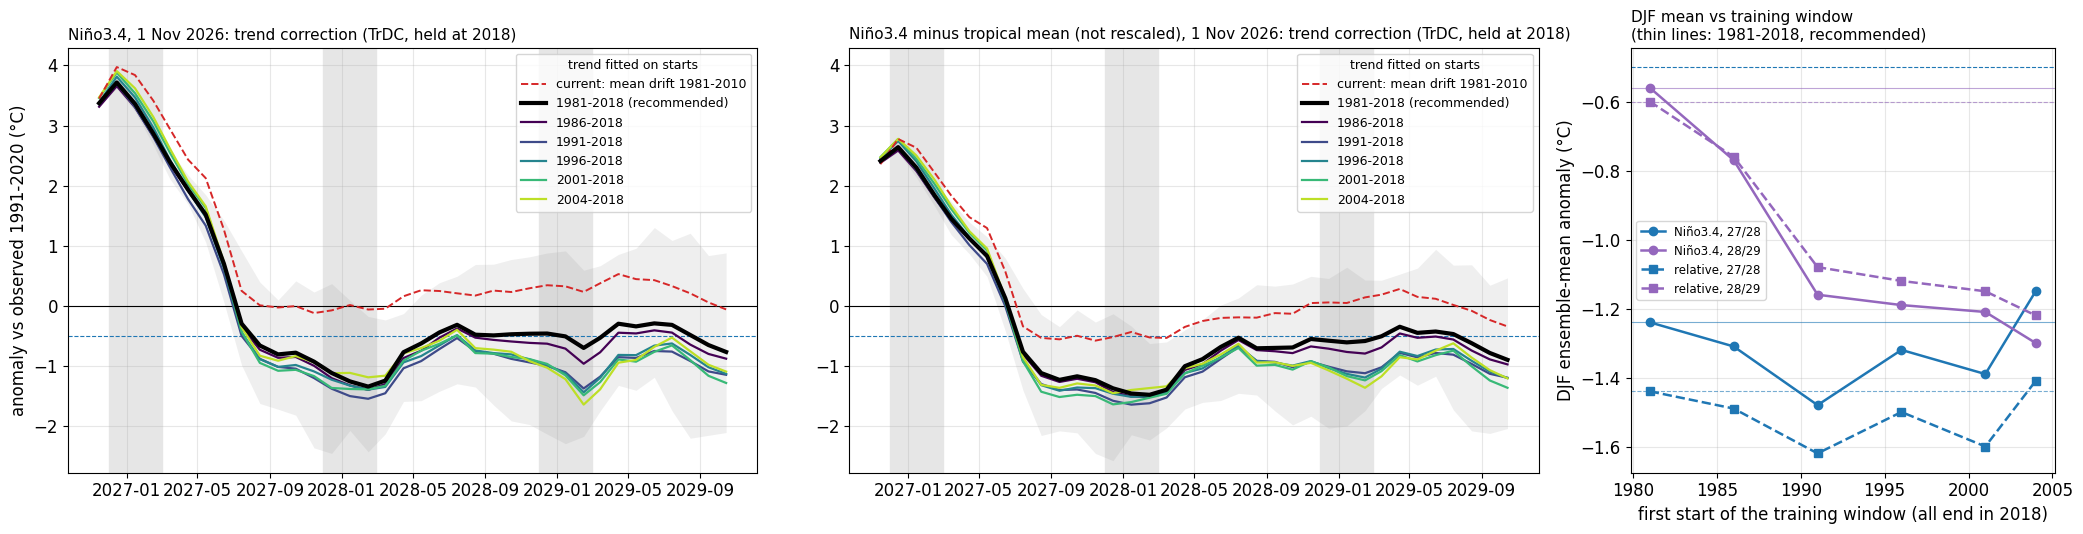

,index,trend starts,starts,trend term DJF 27/28 (°C),DJF 27/28 mean,P(LN 27/28),DJF 28/29 mean,P(LN 28/29),P(both),step Oct→Nov 2028 (°C)
0,Nino3.4,1981-2018 (recommended),38,0.98,-1.24,0.80,-0.56,0.50,0.40,0.01
1,Nino3.4,1986-2018,33,0.95,-1.31,0.80,-0.77,0.60,0.50,-0.02
2,Nino3.4,1991-2018,28,1.04,-1.48,0.83,-1.16,0.67,0.60,-0.06
3,Nino3.4,1996-2018,23,0.63,-1.32,0.80,-1.19,0.67,0.57,-0.08
4,Nino3.4,2001-2018,18,0.62,-1.39,0.83,-1.21,0.67,0.60,-0.04
5,Nino3.4,2004-2018,15,0.16,-1.15,0.80,-1.30,0.73,0.63,-0.16
6,Relative,1981-2018 (recommended),38,0.76,-1.44,0.87,-0.60,0.50,0.47,0.14
7,Relative,1986-2018,33,0.73,-1.49,0.87,-0.76,0.50,0.47,0.11
8,Relative,1991-2018,28,0.80,-1.62,0.90,-1.08,0.70,0.67,0.09
9,Relative,1996-2018,23,0.49,-1.50,0.87,-1.12,0.73,0.67,0.08


In [9]:
TR_END = REF_YEARS[1]                      # every window ends at the last start; the trend is held there
tr_starts = list(range(int(YEARS[0]), TR_END - WINDOW + 2, STEP))
if tr_starts[-1] != TR_END - WINDOW + 1:
    tr_starts.append(TR_END - WINDOW + 1)
TR_BASES = {f"{s}-{TR_END}" + (" (recommended)" if s == YEARS[0] else ""): (s, TR_END) for s in tr_starts}
tr_colors = ["k"] + list(plt.cm.viridis(np.linspace(0, 0.9, len(tr_starts) - 1)))
CURRENT = (1981, 2010)
rows = []
x = [target(YEAR, L).to_timestamp() + pd.Timedelta(days=14) for L in range(NLEAD)]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={"width_ratios": [1.3, 1.3, 0.8]})
for ax, kind in zip(axes[:2], ("Nino3.4", "Relative")):
    _, fc, _ = data(kind)
    sub0, _ = correction(kind, "fixed", CURRENT, YEAR, NLEAD)
    ax.plot(x, (fc - sub0[None, :]).mean(0), color="tab:red", lw=1.4, ls="--", zorder=4,
            label=f"current: mean drift {CURRENT[0]}-{CURRENT[1]}")
    for (lab, win), c in zip(TR_BASES.items(), tr_colors):
        sub, _ = correction(kind, "T1", win, YEAR, NLEAD, trend_year=TR_END)
        sub_mean, _ = correction(kind, "fixed", win, YEAR, NLEAD)
        a = fc - sub[None, :]                                       # TrDC of win held at 2018, observed OBS_BASE reference
        default = win[0] == YEARS[0]
        ax.plot(x, a.mean(0), color=c, lw=3 if default else 1.6, zorder=5 if default else 3, label=lab)
        if default:
            ax.fill_between(x, *np.percentile(a, [10, 90], axis=0), color="0.5", alpha=0.12, lw=0)
        v = {w: djf(a, first) for w, first in WINTERS.items()}
        ln = {w: v[w] <= THRESHOLD for w in v}
        term = sub - sub_mean                                       # trend term: TrDC minus the window's mean drift
        rows.append({"index": kind, "trend starts": lab, "first start": win[0], "starts": int(((YEARS >= win[0]) & (YEARS <= win[1])).sum()),
                     "trend term DJF 27/28 (°C)": round(float(djf(term, WINTERS["2027/28"])), 2),
                     "DJF 27/28 mean": round(v["2027/28"].mean(), 2), "P(LN 27/28)": round(ln["2027/28"].mean(), 2),
                     "DJF 28/29 mean": round(v["2028/29"].mean(), 2), "P(LN 28/29)": round(ln["2028/29"].mean(), 2),
                     "P(both)": round((ln["2027/28"] & ln["2028/29"]).mean(), 2),
                     "step Oct→Nov 2028 (°C)": round(float(a.mean(0)[NLEAD_REF] - a.mean(0)[NLEAD_REF - 1]), 2)})
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
    for first in WINTERS.values():
        ax.axvspan(x[first] - pd.Timedelta(days=14), x[first + 2] + pd.Timedelta(days=14), color="0.9", zorder=0)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean (not rescaled)'}, 1 Nov 2026: "
                 f"trend correction (TrDC, held at {TR_END})", loc="left", fontsize=11)
    ax.legend(fontsize=9, loc="upper right", title="trend fitted on starts", title_fontsize=9)
axes[0].set_ylabel(f"anomaly vs observed {OBS_BASE[0]}-{OBS_BASE[1]} (°C)")
axes[1].sharey(axes[0])
p_trdc = pd.DataFrame(rows)
ax = axes[2]
for kind, ls, mk in (("Nino3.4", "-", "o"), ("Relative", "--", "s")):
    sub = p_trdc[p_trdc["index"] == kind]
    dflt = sub[sub["first start"] == YEARS[0]].iloc[0]
    for col, c in (("DJF 27/28 mean", "tab:blue"), ("DJF 28/29 mean", "tab:purple")):
        ax.plot(sub["first start"], sub[col], color=c, ls=ls, marker=mk, lw=1.8,
                label=f"{'Niño3.4' if kind == 'Nino3.4' else 'relative'}, {col.split()[1]}")
        ax.axhline(dflt[col], color=c, ls=ls, lw=0.8, alpha=0.6)
ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
ax.set_xlabel(f"first start of the training window (all end in {TR_END})")
ax.set_ylabel("DJF ensemble-mean anomaly (°C)")
ax.set_title(f"DJF mean vs training window\n(thin lines: {YEARS[0]}-{TR_END}, recommended)", loc="left", fontsize=11)
ax.legend(fontsize=8.5)
fig.tight_layout()
save(fig, "drift_trend", "nov2026_trdc_by_training_starts")
plt.show()
p_trdc.to_csv(DATA_DIR / "nov2026_la_nina_trdc_by_training_starts.csv", index=False)
display(p_trdc.drop(columns="first start"))

### 3d. Test in time of the training window

Does the trend correction verify better with all starts or with a recent window? As section 2: every correction is
built from starts that end in 2008 and verified on the 2009-2018 starts. Windows: 1981-2008 (the analogue of the
recommended 1981-2018) and windows starting 5 years later (1986-2008, 1991-2008, 1994-2008, at least 15 starts).
Variants: TrDC **held at 2008** (the last training start, the analogue of "held at 2018" for 2026), TrDC
**extrapolated** to each verification start (section 2's T1), and the **mean drift** of the same window. Scores: MSE
of the ensemble mean and Brier score for La Niña (DJF ≤ −0.5 °C), years 1 and 2, as the difference from TrDC
1981-2008 held at 2008, with the 90% bootstrap interval over the 10 verification years.

**Result (Niño3.4).**

| TrDC held at 2008, MSE difference from 1981-2008 (90%) | year 1 | year 2 | bias year 1 / year 2 (°C) |
|---|---|---|---|
| 1981-2008 | 0 | 0 | −0.19 / +0.65 |
| 1986-2008 | **+0.07 (+0.04 to +0.10)** | **−0.08 (−0.15 to −0.01)** | −0.33 / +0.58 |
| 1991-2008 | **+0.14 (+0.10 to +0.19)** | −0.32 (−0.68 to +0.05) | −0.42 / +0.31 |
| 1994-2008 | **+0.10 (+0.06 to +0.14)** | **−0.18 (−0.34 to −0.01)** | −0.37 / +0.49 |

* **No window wins in both years.** The shorter windows over-correct year 1 (cold bias −0.33 to −0.42 °C;
  significantly worse MSE and La Niña Brier score) and correct year 2 a little better (MSE −0.08 to −0.32; the
  year-2 Brier score does not separate them, −0.03 to 0.00).
* **The window matters much less than using a trend at all.** Against the mean drift of the same window, every
  TrDC improves year 2 by 0.55-1.2 in MSE; the spread between windows is 0.3.
* **Hold, do not extrapolate.** Extrapolating the trend to the verification start is significantly worse in year 1
  for every window (+0.10 to +0.60) and not significantly better in year 2; holding it at the last start is the
  better choice, as used for 2026.
* **All corrections remain too warm in year 2** (+0.3 to +0.65 °C), so the trend correction is, if anything, too
  weak in year 2; the shorter windows, which give the stronger 2028/29 La Niña in 3c, are the ones closer to
  unbiased there.

The relative index gives the same picture (year 1: +0.04 to +0.08; year 2: −0.04 to −0.20). So the full record is
kept as the default because it is best in year 1 and costs little in year 2, not because it is best overall; the
recent windows (P(La Niña 2028/29) ≈ 0.7 in 3c) are a supported upper end for year 2.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/03_drift_trend_and_test/figures/fig_drift_trend_test_in_time_trdc_by_training_window.png


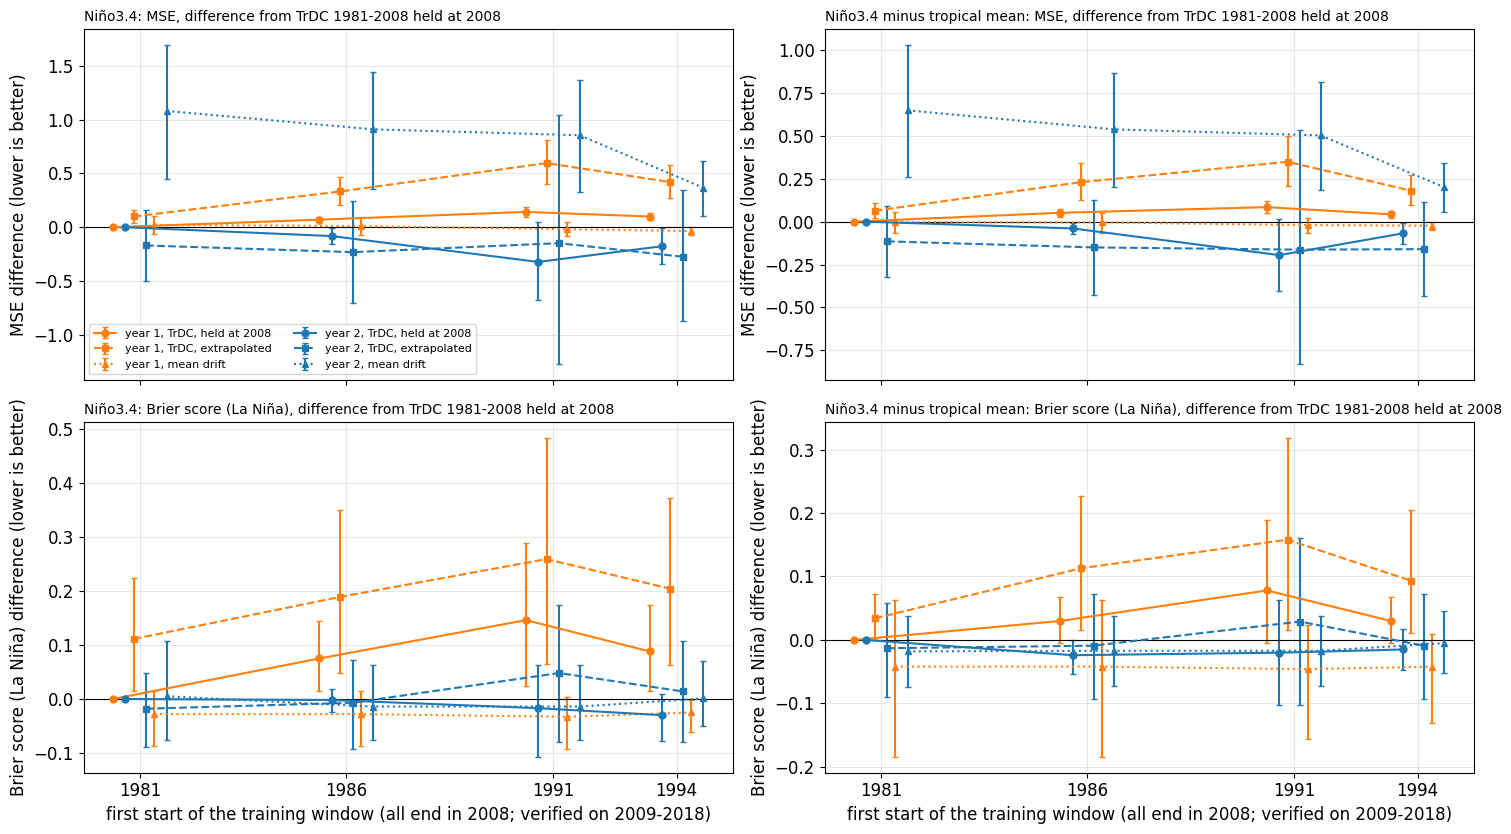

,index,window,variant,winter,mean bias (°C),RMSE (°C),Brier (La Niña),MSE diff (90%),Brier diff (90%)
0,Nino3.4,1981-2008,"TrDC, held at 2008",year 1,-0.19,0.28,0.041,+0.00 (+0.00 to +0.00),+0.000 (+0.000 to +0.000)
1,Nino3.4,1981-2008,"TrDC, held at 2008",year 2,0.65,1.24,0.234,+0.00 (+0.00 to +0.00),+0.000 (+0.000 to +0.000)
2,Nino3.4,1981-2008,"TrDC, extrapolated",year 1,-0.36,0.42,0.152,+0.10 (+0.04 to +0.16),+0.111 (+0.015 to +0.224)
3,Nino3.4,1981-2008,"TrDC, extrapolated",year 2,0.41,1.17,0.216,-0.17 (-0.50 to +0.16),-0.018 (-0.088 to +0.049)
4,Nino3.4,1981-2008,mean drift,year 1,0.24,0.31,0.013,+0.02 (-0.07 to +0.11),-0.028 (-0.087 to +0.014)
5,Nino3.4,1981-2008,mean drift,year 2,1.23,1.62,0.239,+1.08 (+0.44 to +1.69),+0.005 (-0.076 to +0.108)
6,Nino3.4,1986-2008,"TrDC, held at 2008",year 1,-0.33,0.38,0.116,+0.07 (+0.04 to +0.10),+0.075 (+0.015 to +0.144)
7,Nino3.4,1986-2008,"TrDC, held at 2008",year 2,0.58,1.20,0.232,-0.08 (-0.15 to -0.01),-0.002 (-0.024 to +0.018)
8,Nino3.4,1986-2008,"TrDC, extrapolated",year 1,-0.60,0.64,0.230,+0.33 (+0.21 to +0.47),+0.189 (+0.048 to +0.349)
9,Nino3.4,1986-2008,"TrDC, extrapolated",year 2,0.29,1.14,0.227,-0.23 (-0.71 to +0.25),-0.007 (-0.092 to +0.073)


In [10]:
# windows ending at the last training start (2008), as in section 2; at least WINDOW starts
TR_TRAIN_END = TRAIN[1]
win_starts = list(range(int(YEARS[0]), TR_TRAIN_END - WINDOW + 2, STEP))
if win_starts[-1] != TR_TRAIN_END - WINDOW + 1:
    win_starts.append(TR_TRAIN_END - WINDOW + 1)
# variants: trend held at the last training start (the analogue of "held at 2018" for 2026) or extrapolated
# to each verification start (section 2's T1); the mean drift of the same window for reference
VARIANTS = {"TrDC, held at 2008": ("T1", TR_TRAIN_END), "TrDC, extrapolated": ("T1", None), "mean drift": ("fixed", None)}
REF_KEY = (win_starts[0], "TrDC, held at 2008")


def verify_win(kind, method, starts, trend_year):
    ref, _, obs = data(kind)
    fc, ob = [], []
    for y in range(VERIFY[0], VERIFY[1] + 1):
        sub, oref = correction(kind, method, starts, y, NLEAD_REF, trend_year=trend_year)
        k = int(np.where(YEARS == y)[0][0])
        fc.append(ref[k] - sub[None, :])
        ob.append(np.array([obs[target(y, L)] for L in range(NLEAD_REF)]) - oref)
    return np.array(fc), np.array(ob)


rows, sc = [], {}
for kind in ("Nino3.4", "Relative"):
    for s0 in win_starts:
        for var, (method, ty) in VARIANTS.items():
            fc, ob = verify_win(kind, method, (s0, TR_TRAIN_END), ty)
            em = np.nanmean(fc, axis=1)
            for lab, first in DJF_LEADS.items():
                f, o_, e = djf(fc, first), djf(ob, first), djf(em, first)
                p = np.nanmean(f <= THRESHOLD, axis=1)
                evt = (o_ <= THRESHOLD).astype(float)
                sc[(kind, s0, var, lab)] = {"se": (e - o_) ** 2, "bs": (p - evt) ** 2}
                rows.append({"index": kind, "window": f"{s0}-{TR_TRAIN_END}", "first start": s0, "variant": var, "winter": lab,
                             "mean bias (°C)": round(np.mean(e - o_), 2), "RMSE (°C)": round(np.sqrt(np.mean((e - o_) ** 2)), 2),
                             "Brier (La Niña)": round(np.mean((p - evt) ** 2), 3)})
win_test = pd.DataFrame(rows)

# 90% bootstrap (verification years resampled) of each score's difference from TrDC 1981-2008 held at 2008
rng = np.random.default_rng(0)
boot = rng.integers(0, nyr, (N_BOOT, nyr))
diff = {}
for (kind, s0, var, lab), s in sc.items():
    b0 = sc[(kind, *REF_KEY, lab)]
    for metric in ("se", "bs"):
        d = s[metric][boot].mean(1) - b0[metric][boot].mean(1)
        diff[(kind, s0, var, lab, metric)] = (float(np.mean(s[metric] - b0[metric])), *np.percentile(d, [5, 95]))
win_test["MSE diff (90%)"] = [
    "{:+.2f} ({:+.2f} to {:+.2f})".format(*diff[(r["index"], r["first start"], r["variant"], r["winter"], "se")]) for _, r in win_test.iterrows()]
win_test["Brier diff (90%)"] = [
    "{:+.3f} ({:+.3f} to {:+.3f})".format(*diff[(r["index"], r["first start"], r["variant"], r["winter"], "bs")]) for _, r in win_test.iterrows()]
win_test.to_csv(DATA_DIR / "test_in_time_trdc_by_training_window.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), sharex=True)
styles = {"TrDC, held at 2008": ("-", "o"), "TrDC, extrapolated": ("--", "s"), "mean drift": (":", "^")}
for col, kind in enumerate(("Nino3.4", "Relative")):
    for row, (metric, mlab) in enumerate((("se", "MSE"), ("bs", "Brier score (La Niña)"))):
        ax = axes[row, col]
        for lab, c in (("year 1", "tab:orange"), ("year 2", "tab:blue")):
            for k, (var, (ls, mk)) in enumerate(styles.items()):
                xs = np.array(win_starts) + (k - 1) * 0.5 + (0.15 if lab == "year 2" else -0.15)
                m, lo, hi = np.array([diff[(kind, s0, var, lab, metric)] for s0 in win_starts]).T
                ax.errorbar(xs, m, yerr=[m - lo, hi - m], color=c, ls=ls, marker=mk, ms=5, lw=1.5, capsize=2,
                            label=f"{lab}, {var}")
        ax.axhline(0, color="k", lw=0.8)
        ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean'}: {mlab}, "
                     f"difference from TrDC {REF_KEY[0]}-{TR_TRAIN_END} held at {TR_TRAIN_END}", loc="left", fontsize=10)
        ax.set_ylabel(f"{mlab} difference (lower is better)")
        if row == 1:
            ax.set_xlabel(f"first start of the training window (all end in {TR_TRAIN_END}; verified on {VERIFY[0]}-{VERIFY[1]})")
        ax.set_xticks(win_starts)
axes[0, 0].legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "drift_trend", "test_in_time_trdc_by_training_window")
plt.show()
with pd.option_context("display.max_columns", 30, "display.width", 250, "display.max_rows", 100):
    display(win_test.drop(columns="first start"))

### Findings

**1. The drift trends with the start year.** The Niño3.4 drift (model minus observed) rises by +0.20 °C/decade
in the year-1 DJF (r = 0.61 with the start year) and +0.53 °C/decade in the year-2 DJF (r = 0.52): over the
starts the model becomes warmer in Niño3.4 relative to observations, also in the relative index. This is the
known pattern of models warming the eastern equatorial Pacific more than observed. The year-2 values scatter
by 1-3 °C from start to start (the error of each start's ENSO forecast), so the trend is uncertain, and it is
set largely by the 2006-2016 starts; the latest starts (2013, 2017, 2018) lie below the fitted line.

**2. Test in time (drift from 1981-2008, verified on 2009-2018):**

| Niño3.4 | bias year 1 | bias year 2 | RMSE year 2 | Brier LN year 2 |
|---|---|---|---|---|
| fixed 1981-2008 | +0.24 | +1.23 | 1.62 | 0.24 |
| fixed 1991-2008 | +0.13 | +1.13 | 1.55 | 0.22 |
| fixed 1994-2008 (last 15) | +0.01 | +0.89 | 1.38 | 0.24 |
| T1 drift trend | −0.36 | +0.41 | 1.17 | 0.22 |
| T2 climatology trend (Kharin) | −0.09 | +0.40 | 1.16 | 0.25 |

* Every method that weights the recent starts reduces the year-2 bias and MSE significantly (90% bootstrap
  intervals of the MSE difference exclude zero for the last-15, T1 and T2 drifts). T2 and the last-15 window
  also remove the year-1 bias; T1 over-corrects year 1 (−0.36 °C, significantly worse Brier score). **T2
  verifies best overall.**
* Even T2 leaves a +0.4 °C warm bias in year 2 over 2009-2018: the drift change was faster than any of these
  methods anticipated.
* The Brier score for La Niña cannot separate the methods: 3 observed La Niña winters in 10 years give
  differences within ±0.15 with intervals spanning zero. (For T2 the observed reference is the observed trend,
  so its events differ: 1 event for the relative index; its Brier scores are not comparable.)

**3. The 2026 forecast moves far toward La Niña under every recency-aware correction** (Niño3.4; relative
index similar):

| drift correction | P(LN 27/28) | P(LN 28/29) | P(both) |
|---|---|---|---|
| fixed 1981-2010 (current) | 0.30 | 0.27 | 0.10 |
| fixed 1991-2018 | 0.57 | 0.40 | 0.23 |
| fixed 2004-2018 (last 15) | 0.73 | 0.63 | 0.50 |
| T2 climatology trend, held at 2018 | 0.80 | 0.50 | 0.40 |
| T1 drift trend, held at 2018 | 0.80 | 0.50 | 0.40 |
| T2 climatology trend, at 2026 | 0.83 | 0.63 | 0.57 |
| T1 drift trend, at 2026 | 0.87 | 0.60 | 0.57 |

The trend-aware results land well past the 1991-2018 result, as expected; even without extrapolating past the
last start (held at 2018) P(La Niña 2027/28) is 0.80. In year 3 the trend term is held at its lead-23 value:
an earlier version copied it by target month together with the mean drift, which continued its growth into
year 3 (P(LN 28/29) 0.67 for T2 at 2018) and left a step of −0.27 °C in Nov 2028. The step is now within
±0.06 °C for every Niño3.4 correction except the last-15 drift (−0.16).

**4. Caveats.** (a) At 2026 the trend is extrapolated 8 years past the last start, above every start since
2016; holding it at 2018 is the conservative choice. (b) Part of the drift trend may be observed decadal
variability (a more La Niña-like Pacific in the 2010s) rather than a model property; if that reverses, the
trend-aware corrections over-correct. (c) T2's anomalies are relative to a trend-following base (like CPC's
moving base and the relative index), so its La Niña threshold is not the same as the fixed-base methods'.

**Suggested for the outlook:** T2 held at the last start (2018) as the central estimate,
P(La Niña 2027/28) ≈ 0.80, P(La Niña 2028/29) ≈ 0.50, P(both) ≈ 0.40, with the range from the fixed
1991-2018 drift (0.57 / 0.40 / 0.23) to T2 at 2026 (0.83 / 0.63 / 0.57). `05_drift_correction_methods` compares
this with the mean-drift and initial-condition corrections. The 1981-2010 drift (0.30 / 0.27 /
0.10) verifies worst on the recent starts and should not be the headline.